# The electron ladder: does a learned site Hamiltonian transfer from H₂⁺ to H₃?

**Idea.** Instead of learning an energy, learn a small Hamiltonian whose matrix elements are two-centre functions of interatomic distance, and get every charge and spin state by diagonalising it. If the *same* functions describe H₂⁺, H₂, H₃²⁺ and H₃⁺, they should predict H₃ with **no H₃ data at all**. That transfer is the test of whether the approach has legs.

**Model** (one orthogonal site orbital per H; an extended Hubbard / diatomics-in-molecules-like form):

$$\hat H=\sum_i \varepsilon_i\,\hat n_i+\sum_{i\ne j,\sigma} t_{ij}\,\hat a^\dagger_{i\sigma}\hat a_{j\sigma}+U\sum_i \hat n_{i\uparrow}\hat n_{i\downarrow}+\sum_{i<j}\big[V_{ij}\,\hat n_i\hat n_j+K_{ij}\,\hat K_{ij}+X_{ij}\,\hat B_{ij}\big]+\sum_{i<j}\frac{1}{r_{ij}}$$

| Term | Physics | Form |
|---|---|---|
| ε_i = ε₀ + Σⱼ w(r_ij) | site energy, attraction to other nuclei | w = −1/r + short-range |
| t(r_ij) · (1 + Σₖ a(r_ik) + a(r_jk)) | hopping (resonance), optional 3-body screening | short-range |
| U | on-site repulsion (ionic structures) | fixed from H⁻ and H in the same basis |
| V(r) | inter-site Coulomb | +1/r + short-range |
| K(r) | exchange + pair hopping (spin coupling) | short-range |
| X(r) | bond-charge integrals (ii\|ij): hopping that depends on the other electron, a proxy for orbital relaxation | short-range |

Every short-range part is a linear combination of Slater 1s overlaps S_ζ(r), the descriptor that interpolated best in the first notebook, so each vanishes at large r and the asymptotes are exact by construction (ε₀ = E(H), U from E(H⁻)).

**Ladder**
| Rung | System | e⁻ | New physics switched on |
|---|---|---|---|
| 1 | H₂⁺, H₃²⁺ | 1 | hopping, site energies; is one-electron hopping two-centre? |
| 2 | H₂ (S₀, T₁) | 2 | on-site repulsion, Coulomb, exchange |
| 3 | H₃⁺ | 2 | three-centre two-electron bond |
| 4 | H₃⁺ triplet, H₃²⁺ excited | 1–2 | more three-centre states, still no H₃ |
| test | **H₃** | 3 | three-electron spin coupling, never trained on |

Baseline: the **London equation** (LEPS with Sato = 0) built from the exact H₂ singlet and triplet curves, which uses only two-body data and no fitting.

References are FCI/cc-pVDZ, exact in that basis.

In [1]:
import time, itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.optimize import least_squares
from scipy.interpolate import CubicSpline
from pyscf import gto, scf, fci, ao2mo

KCAL, BOHR, BASIS = 627.5095, 0.529177, 'cc-pvdz'
C1, C2, C3, C4, CREF = '#2a78d6', '#eb6834', '#1baf7a', '#e87ba4', '#3d3d3a'
DIVERGE = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#e9e8e4', '#eb6834'])
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6,
                     'lines.linewidth': 2, 'font.size': 10, 'legend.frameon': False})

## 1 · Exact references

FCI uses the orbitals that diagonalise the one-electron Hamiltonian. FCI in the full orbital space doesn't depend on that choice, and it avoids SCF convergence trouble at stretched geometries.

In [2]:
def make_mol(coords_ang, charge, spin):
    atoms = '; '.join(f'H {x:.6f} {y:.6f} 0' for x, y in coords_ang)
    return gto.M(atom=atoms, basis=BASIS, charge=charge, spin=spin, verbose=0)

def exact_energies(coords_ang, charge, nelec, nroots=1):
    # nelec = (n_alpha, n_beta); returns the lowest nroots total energies in that spin sector
    mol = make_mol(coords_ang, charge, nelec[0] - nelec[1])
    h, S = mol.intor('int1e_kin') + mol.intor('int1e_nuc'), mol.intor('int1e_ovlp')
    e1, C = np.linalg.eigh(np.linalg.inv(np.linalg.cholesky(S)) @ h @ np.linalg.inv(np.linalg.cholesky(S)).T)
    C = np.linalg.solve(np.linalg.cholesky(S).T, C)
    enuc = mol.energy_nuc()
    if sum(nelec) == 1:
        return e1[:nroots] + enuc
    norb = C.shape[1]
    h1 = C.T @ h @ C
    eri = ao2mo.restore(1, ao2mo.kernel(mol, C), norb)
    solver = fci.direct_spin1.FCI(); solver.conv_tol = 1e-10
    e, _ = solver.kernel(h1, eri, norb, nelec, ecore=enuc, nroots=nroots)
    return np.atleast_1d(e)[:nroots]

t0 = time.time()
E_H = exact_energies([(0, 0)], 0, (1, 0))[0]
E_Hm = exact_energies([(0, 0)], -1, (1, 1))[0]
print(f'E(H) = {E_H:.6f}  E(H-) = {E_Hm:.6f}  ->  U = {E_Hm - 2 * E_H:.4f} Eh')

E(H) = -0.499278  E(H-) = -0.469857  ->  U = 0.5287 Eh


In [3]:
import os
r_di = np.concatenate([np.linspace(0.45, 3.0, 52), np.linspace(3.1, 8.0, 25)])
def tri_coords(r1, r2, theta_deg):
    # angle theta at the middle atom
    th = np.radians(theta_deg)
    return [(-r1, 0.0), (0.0, 0.0), (-r2 * np.cos(th), r2 * np.sin(th))]
g_lin, g_bent = np.linspace(0.6, 3.6, 16), np.linspace(0.6, 3.0, 9)
geoms = [(a, b, 180.0) for a in g_lin for b in g_lin]
geoms += [(a, b, th) for th in (60.0, 90.0, 120.0) for a in g_bent for b in g_bent]
geoms = np.array(geoms)

CACHE = 'ladder_refs.npz'          # delete to recompute (about 2 minutes)
if os.path.exists(CACHE):
    z = np.load(CACHE)
    di = {k: z[k] for k in ['H2+', 'H2_S', 'H2_T']}
    tri = {k: z[k] for k in ['H3++', 'H3+', 'H3', 'H3+_T', 'H3++_x']}
else:
    di = {'H2+': [], 'H2_S': [], 'H2_T': []}
    for r in r_di:
        xy = [(0, 0), (r, 0)]
        di['H2+'].append(exact_energies(xy, 1, (1, 0), nroots=2))
        di['H2_S'].append(exact_energies(xy, 0, (1, 1))[0])
        di['H2_T'].append(exact_energies(xy, 0, (2, 0))[0])
    tri = {'H3++': [], 'H3+': [], 'H3': [], 'H3+_T': [], 'H3++_x': []}
    for a, b, th in geoms:
        xy = tri_coords(a, b, th)
        tri['H3++_x'].append(exact_energies(xy, 2, (1, 0), nroots=3))
        tri['H3++'].append(tri['H3++_x'][-1][0])
        tri['H3+'].append(exact_energies(xy, 1, (1, 1))[0])
        tri['H3+_T'].append(exact_energies(xy, 1, (2, 0))[0])
        tri['H3'].append(exact_energies(xy, 0, (2, 1))[0])
    di = {k: np.array(v) for k, v in di.items()}
    tri = {k: np.array(v) for k, v in tri.items()}
    np.savez(CACHE, **di, **tri)
print(f'{len(r_di)} diatomic and {len(geoms)} triatomic geometries, {time.time() - t0:.0f} s')

77 diatomic and 499 triatomic geometries, 25 s


## 2 · The site Hamiltonian

Built in the occupation-number basis with Jordan–Wigner fermion operators and projected onto each (N_α, N_β) sector. For three sites the largest block is 9×9, so every geometry and charge state is solved exactly in microseconds. Every term is linear in its parameter values, so operator matrices are precomputed once per sector.

In [5]:
def fermion_ops(nsite):
    nso = 2 * nsite                      # spin orbital p = 2*i + sigma
    I2, Z = np.eye(2), np.diag([1.0, -1.0])
    a1 = np.array([[0.0, 1.0], [0.0, 0.0]])  # basis (|0>,|1>): a|1> = |0>
    ops = []
    for p in range(nso):
        m = np.array([[1.0]])
        for q in range(nso):
            m = np.kron(m, Z if q < p else (a1 if q == p else I2))
        ops.append(m)
    return ops

def sector_operators(nsite, na, nb):
    a = fermion_ops(nsite)
    ad = [x.T for x in a]
    nso, dim = 2 * nsite, 4 ** nsite
    occ = np.array([[(s >> (nso - 1 - p)) & 1 for p in range(nso)] for s in range(dim)])
    keep = np.where((occ[:, 0::2].sum(1) == na) & (occ[:, 1::2].sum(1) == nb))[0]
    P = lambda M: M[np.ix_(keep, keep)]
    num = lambda i, s: ad[2 * i + s] @ a[2 * i + s]
    pairs = list(itertools.combinations(range(nsite), 2))
    N = np.array([P(num(i, 0) + num(i, 1)) for i in range(nsite)])
    HOP = np.array([P(sum(ad[2 * i + s] @ a[2 * j + s] + ad[2 * j + s] @ a[2 * i + s] for s in (0, 1))) for i, j in pairs])
    D = P(sum(num(i, 0) @ num(i, 1) for i in range(nsite)))
    NN = np.array([P((num(i, 0) + num(i, 1)) @ (num(j, 0) + num(j, 1))) for i, j in pairs])
    def two_body(eri):
        H = 0
        for p, q, r, s in zip(*np.nonzero(eri)):
            for sg in (0, 1):
                for tu in (0, 1):
                    H = H + 0.5 * eri[p, q, r, s] * ad[2 * p + sg] @ ad[2 * r + tu] @ a[2 * s + tu] @ a[2 * q + sg]
        return P(H)
    EX = []
    for i, j in pairs:
        e = np.zeros((nsite,) * 4)
        e[i, j, i, j] = e[j, i, j, i] = e[i, j, j, i] = e[j, i, i, j] = 1.0
        EX.append(two_body(e))
    XB = []                               # bond-charge integrals (ii|ij), (jj|ji): occupation-dependent hopping
    for i, j in pairs:
        e = np.zeros((nsite,) * 4)
        for p, q in [(i, j), (j, i)]:
            e[p, p, p, q] = e[p, p, q, p] = e[p, q, p, p] = e[q, p, p, p] = 1.0
        XB.append(two_body(e))
    return dict(N=N, HOP=HOP, D=D, NN=NN, EX=np.array(EX), XB=np.array(XB), pairs=pairs, dim=len(keep))

SECTORS = {(n, na, nb): sector_operators(n, na, nb) for n, na, nb in
           [(1, 1, 1), (2, 1, 0), (2, 1, 1), (2, 2, 0), (3, 1, 0), (3, 1, 1), (3, 2, 0), (3, 2, 1)]}

# sanity: one electron on two sites gives eps +/- t
o = SECTORS[(2, 1, 0)]
print(np.linalg.eigvalsh(-0.5 * o['N'].sum(0) - 0.1 * o['HOP'][0]))   # expect [-0.6, -0.4]

[-0.6 -0.4]


In [6]:
ZETAS = np.array([0.5, 0.7, 0.9, 1.1, 1.4])          # Slater exponents (1/bohr)
NF = len(ZETAS)

def slater_features(r_bohr):
    p = np.asarray(r_bohr)[..., None] * ZETAS
    return np.exp(-p) * (1 + p + p ** 2 / 3)

EPS0, U0 = E_H, E_Hm - 2 * E_H
BLOCKS = ['t', 'w', 'V', 'K', 'X', 'a']                 # coefficient blocks, NF each
def unpack(theta):
    return {k: theta[i * NF:(i + 1) * NF] for i, k in enumerate(BLOCKS)}

class Dataset:
    # all structures of one sector, stacked for batched diagonalisation
    def __init__(self, name, sector, coords_ang, targets, root=0):
        self.name, self.sector, self.root = name, sector, root
        self.ops = SECTORS[sector]
        X = np.array(coords_ang) / BOHR                      # (S, n, 2) in bohr
        n = X.shape[1]
        R = np.linalg.norm(X[:, :, None] - X[:, None], axis=-1)
        self.R = R
        self.F = slater_features(np.where(R > 0, R, 1.0))    # (S, n, n, NF)
        self.inv = np.where(R > 0, 1.0 / np.where(R > 0, R, 1.0), 0.0)
        self.pairs = self.ops['pairs']
        self.enn = np.array([sum(self.inv[s, i, j] for i, j in self.pairs) for s in range(len(X))])
        self.y = np.asarray(targets)
        self.n = n
    def predict(self, theta):
        c = unpack(theta)
        S, n = len(self.y), self.n
        off = ~np.eye(n, dtype=bool)
        w = (-self.inv + self.F @ c['w']) * off              # (S, n, n)
        eps = EPS0 + w.sum(-1)
        H = np.einsum('si,ijk->sjk', eps, self.ops['N']) + U0 * self.ops['D'][None]
        for p, (i, j) in enumerate(self.pairs):
            r_t = self.F[:, i, j] @ c['t']
            if n > 2:
                k = [m for m in range(n) if m not in (i, j)]
                scr = 1 + sum(self.F[:, i, m] @ c['a'] + self.F[:, j, m] @ c['a'] for m in k)
                r_t = r_t * scr
            V = self.inv[:, i, j] + self.F[:, i, j] @ c['V']
            K = self.F[:, i, j] @ c['K']
            X = self.F[:, i, j] @ c['X']
            H += (r_t[:, None, None] * self.ops['HOP'][p] + V[:, None, None] * self.ops['NN'][p]
                  + K[:, None, None] * self.ops['EX'][p] + X[:, None, None] * self.ops['XB'][p])
        H += self.enn[:, None, None] * np.eye(self.ops['dim'])[None]
        return np.linalg.eigvalsh(H)[:, self.root]

# exact-asymptote check: separated atoms and H- must come out exactly
far = Dataset('far', (3, 2, 1), [tri_coords(60, 60, 180)], [0.0])
print(f'3 H far apart: model - 3E(H) = {(far.predict(np.zeros(len(BLOCKS) * NF)) - 3 * E_H)[0]:.2e} Eh')

3 H far apart: model - 3E(H) = 4.44e-16 Eh


## 3 · Datasets and the evaluation window

Geometries with any H–H distance < 0.6 Å, or more than 0.2 Eh (125 kcal/mol) above separated atoms, are excluded from fitting and scoring. That window is everything a hot molecule visits, and leaves out the steep repulsive wall.

In [7]:
def xy_di(r):
    return [(0.0, 0.0), (r, 0.0)]

tri_xy = [tri_coords(a, b, th) for a, b, th in geoms]
rmin_tri = np.array([np.linalg.norm(np.array(x)[:, None] - np.array(x)[None], axis=-1)[np.triu_indices(3, 1)].min() for x in tri_xy])

def window(E, n_atoms_H, rmin):
    return (rmin >= 0.6) & (E - n_atoms_H * E_H <= 0.2)

def subset(name, sector, xy, E, nH, rmin, root=0):
    m = window(E, nH, rmin)
    return Dataset(name, sector, [xy[i] for i in np.where(m)[0]], E[m], root), m

D = {}
D['H2+ σg'], _ = subset('H2+ σg', (2, 1, 0), [xy_di(r) for r in r_di], di['H2+'][:, 0], 1, r_di, 0)
D['H2+ σu'], _ = subset('H2+ σu', (2, 1, 0), [xy_di(r) for r in r_di], di['H2+'][:, 1], 1, r_di, 1)
D['H2 S0'], _ = subset('H2 S0', (2, 1, 1), [xy_di(r) for r in r_di], di['H2_S'], 2, r_di)
D['H2 T1'], _ = subset('H2 T1', (2, 2, 0), [xy_di(r) for r in r_di], di['H2_T'], 2, r_di)
D['H3++'], M3pp = subset('H3++', (3, 1, 0), tri_xy, tri['H3++'], 1, rmin_tri)
D['H3+'], M3p = subset('H3+', (3, 1, 1), tri_xy, tri['H3+'], 2, rmin_tri)
D['H3+ T'], _ = subset('H3+ T', (3, 2, 0), tri_xy, tri['H3+_T'], 2, rmin_tri)
D['H3++ x'], _ = subset('H3++ x', (3, 1, 0), tri_xy, tri['H3++_x'][:, 1], 1, rmin_tri, root=1)
D['H3'], M3 = subset('H3', (3, 2, 1), tri_xy, tri['H3'], 3, rmin_tri)
for k, d in D.items():
    print(f'{k:7s} {len(d.y):4d} points')

H2+ σg    74 points
H2+ σu    59 points
H2 S0     74 points
H2 T1     70 points
H3++     410 points
H3+      499 points
H3+ T    493 points
H3++ x    70 points
H3       499 points


## 4 · Climbing the ladder

Each stage fits only the blocks listed, on only the data listed, then predicts everything else. **H₃ is never in any training set in this section.** Residuals are in kcal/mol; a light ridge penalty keeps coefficients tame. Two H₃ scores are tracked: the whole window, and a *low-energy* subset within 60 kcal/mol of H + H₂, which is where a hot molecule actually spends its time.

In [8]:
def rmse(d, theta):
    return np.sqrt(np.mean((d.predict(theta) - d.y) ** 2)) * KCAL

def fit(theta0, blocks, train, ridge=1e-3):
    free = np.concatenate([np.arange(BLOCKS.index(b) * NF, (BLOCKS.index(b) + 1) * NF) for b in blocks])
    def resid(x):
        th = theta0.copy(); th[free] = x
        r = [(D[k].predict(th) - D[k].y) * KCAL for k in train]
        return np.concatenate(r + [np.sqrt(ridge) * x])
    sol = least_squares(resid, theta0[free], method='trf', x_scale='jac', max_nfev=4000)
    th = theta0.copy(); th[free] = sol.x
    return th

E_H2H = di['H2_S'].min() + E_H                       # H2 + H asymptote
D_H3_all = Dataset('H3 all', (3, 2, 1), tri_xy, tri['H3'])
LOW = M3 & (tri['H3'] - E_H2H <= 60 / KCAL)
def h3_low(E_pred):
    return np.sqrt(np.mean((E_pred[LOW] - tri['H3'][LOW]) ** 2)) * KCAL

COLS = ['H2+ σg', 'H2+ σu', 'H2 S0', 'H2 T1', 'H3++', 'H3++ x', 'H3+', 'H3+ T', 'H3']
def report(theta, label):
    vals = [rmse(D[k], theta) for k in COLS] + [h3_low(D_H3_all.predict(theta))]
    print(f'{label:34s} ' + ' '.join(f'{v:7.1f}' for v in vals))
    return vals

print(f'{"RMSE (kcal/mol)":34s} ' + ' '.join(f'{k:>7s}' for k in COLS + ['H3 low']))
LADDER = ['H2+ σg', 'H2+ σu', 'H3++', 'H2 S0', 'H2 T1', 'H3+']
theta = np.zeros(len(BLOCKS) * NF); theta[:NF] = -0.3
report(theta, '0  untrained')
th1 = fit(theta, ['t', 'w'], ['H2+ σg', 'H2+ σu']);              report(th1, '1  t,w on H2+')
th1b = fit(th1, ['t', 'w', 'a'], ['H2+ σg', 'H2+ σu', 'H3++']);  report(th1b, '1b t,w,a on H2+, H3++')
th2 = fit(th1b, ['V', 'K', 'X'], ['H2 S0', 'H2 T1']);            report(th2, '2  V,K,X on H2 (1-e frozen)')
th3 = fit(th2, BLOCKS, LADDER);                                  report(th3, '3  joint: H2+, H3++, H2, H3+')
th4 = fit(th3, BLOCKS, LADDER + ['H3+ T', 'H3++ x']);            report(th4, '4  + H3+ triplet, H3++ excited')

RMSE (kcal/mol)                     H2+ σg  H2+ σu   H2 S0   H2 T1    H3++  H3++ x     H3+   H3+ T      H3  H3 low
0  untrained                         326.8   187.2   656.1    31.9   515.9    37.5  1310.8   519.2  1177.9  1451.0
1  t,w on H2+                          2.7     0.9    17.5    33.5     4.7     1.0    34.8    24.3    33.3    35.6
1b t,w,a on H2+, H3++                  2.5     3.3    17.2    37.4     3.1     2.6    52.2    27.5    25.5    32.5
2  V,K,X on H2 (1-e frozen)            2.5     3.3     0.3     0.7     3.1     2.6    39.9    10.8    40.9    36.1
3  joint: H2+, H3++, H2, H3+           2.5     3.8     1.8     1.0     3.3     2.6     2.2    12.6    12.6     8.8
4  + H3+ triplet, H3++ excited         2.4     6.0     2.3     6.4     3.7     1.7     2.8     5.1    25.1    24.4


[np.float64(2.3685568211873),
 np.float64(6.010346593064085),
 np.float64(2.3411516241034547),
 np.float64(6.4074128675058795),
 np.float64(3.700754639635677),
 np.float64(1.7193309519512283),
 np.float64(2.7938702426174333),
 np.float64(5.067640693865055),
 np.float64(25.136018008246026),
 np.float64(24.355521301819646)]

## 5 · Baseline: the London equation from exact H₂ curves

$E = Q_1+Q_2+Q_3-\sqrt{\tfrac12[(J_1-J_2)^2+(J_2-J_3)^2+(J_3-J_1)^2]}$ with $Q=(^1E+{^3E})/2$, $J=(^1E-{^3E})/2$ taken directly from the exact H₂ singlet and triplet curves. It is the classic two-body-data answer for H₃ (LEPS with zero Sato parameter) and needs no fitting.

In [9]:
sS, sT = CubicSpline(r_di, di['H2_S'] - 2 * E_H), CubicSpline(r_di, di['H2_T'] - 2 * E_H)
def london(xy):
    x = np.array(xy); r = [np.linalg.norm(x[i] - x[j]) for i, j in [(0, 1), (1, 2), (0, 2)]]
    Q = [(sS(q) + sT(q)) / 2 if q < r_di[-1] else 0 for q in r]
    J = [(sS(q) - sT(q)) / 2 if q < r_di[-1] else 0 for q in r]
    return 3 * E_H + sum(Q) - np.sqrt(0.5 * ((J[0] - J[1]) ** 2 + (J[1] - J[2]) ** 2 + (J[2] - J[0]) ** 2))

E_lon = np.array([london(x) for x in tri_xy])
rmse_lon = np.sqrt(np.mean((E_lon[M3] - tri['H3'][M3]) ** 2)) * KCAL
print(f'London (exact H2 S/T, no fit): H3 window RMSE {rmse_lon:.1f}, low-energy RMSE {h3_low(E_lon):.1f} kcal/mol')

# LEPS: London plus a Sato parameter, either a constant or a short-range function of r.
# Vectorised so it can be fitted cheaply in section 7.
XY = np.array(tri_xy)
RP = np.stack([np.linalg.norm(XY[:, i] - XY[:, j], axis=1) for i, j in [(0, 1), (1, 2), (0, 2)]], 1)
ES = np.where(RP < r_di[-1], sS(np.minimum(RP, r_di[-1])), 0.0)
ET = np.where(RP < r_di[-1], sT(np.minimum(RP, r_di[-1])), 0.0)
def leps(c, idx):
    d = c[0] + (slater_features(RP[idx] / BOHR) @ c[1:] if len(c) > 1 else 0.0) * np.ones_like(RP[idx])
    Q = ((1 + d) * ES[idx] + (1 - d) * ET[idx]) / 2 / (1 + d)
    J = ((1 + d) * ES[idx] - (1 - d) * ET[idx]) / 2 / (1 + d)
    return 3 * E_H + Q.sum(1) - np.sqrt(0.5 * ((J[:, 0] - J[:, 1]) ** 2 + (J[:, 1] - J[:, 2]) ** 2 + (J[:, 2] - J[:, 0]) ** 2))
assert np.allclose(leps(np.zeros(1), np.arange(len(XY))), E_lon)

London (exact H2 S/T, no fit): H3 window RMSE 5.5, low-energy RMSE 2.5 kcal/mol


## 6 · Is the problem the functional form or the data?

Two diagnostics that *do* use H₃ data:
- **Expressiveness:** fit the same functional form to H₃ alone. If it can't fit H₃, physics is missing from the Hamiltonian.
- **Universality:** fit one parameter set to every rung *and* H₃ at once. If that works, a transferable parameter set exists and the lower rungs simply don't pin it down.

In [10]:
th_h3 = fit(th3, BLOCKS, ['H3'])
th_uni = fit(th3, BLOCKS, LADDER + ['H3+ T', 'H3++ x', 'H3'])
print(f'{"RMSE (kcal/mol)":34s} ' + ' '.join(f'{k:>7s}' for k in COLS + ['H3 low']))
report(th_h3, 'H3 only (expressiveness)')
report(th_uni, 'all rungs + H3 (universality)')

RMSE (kcal/mol)                     H2+ σg  H2+ σu   H2 S0   H2 T1    H3++  H3++ x     H3+   H3+ T      H3  H3 low
H3 only (expressiveness)             323.6   285.3     2.1     2.0   672.4   510.1   664.1   654.0     0.6     0.5
all rungs + H3 (universality)          2.6     6.6     1.7     9.1     4.1     1.7     3.4     5.2     2.9     3.0


[np.float64(2.556165949963648),
 np.float64(6.632355354907886),
 np.float64(1.7452164882106191),
 np.float64(9.097418712272994),
 np.float64(4.0853269696358225),
 np.float64(1.7443535507922039),
 np.float64(3.401975190725175),
 np.float64(5.238441973080372),
 np.float64(2.859721013833737),
 np.float64(3.006394250519669)]

## 7 · Few-shot: does the ladder prior make H₃ cheaper to learn?

The practical question for bigger systems: target-system reference data are the expensive part. Add *n* random H₃ points and see how fast each model learns. Test on all remaining H₃ points in the window; three random draws per *n*.

- **site H, ladder + n H₃**: the site Hamiltonian, ladder data plus n H₃ points
- **site H, n H₃ only**: same form, no ladder
- **LEPS, constant Sato**: the London diabatic matrix built from exact H₂ fragment curves, plus 1 learned number
- **LEPS, Sato(r)**: same, with the Sato parameter a short-range function of r (6 numbers)

n =   5: site H, ladder + n H₃  14.5±2.2  site H, n H₃ only  53.6±21.5  LEPS, constant Sato   3.8±1.0  LEPS, Sato(r)   3.6±2.1
n =  10: site H, ladder + n H₃  14.1±2.1  site H, n H₃ only  44.9±14.9  LEPS, constant Sato   3.7±0.6  LEPS, Sato(r)   4.7±1.5
n =  20: site H, ladder + n H₃  10.1±2.1  site H, n H₃ only  22.9±17.2  LEPS, constant Sato   4.0±0.9  LEPS, Sato(r)   1.8±0.6
n =  40: site H, ladder + n H₃   8.1±1.3  site H, n H₃ only  10.5±0.9  LEPS, constant Sato   2.9±0.3  LEPS, Sato(r)   1.7±0.3
n =  80: site H, ladder + n H₃   6.3±0.9  site H, n H₃ only   7.1±1.3  LEPS, constant Sato   2.8±0.6  LEPS, Sato(r)   1.0±0.1


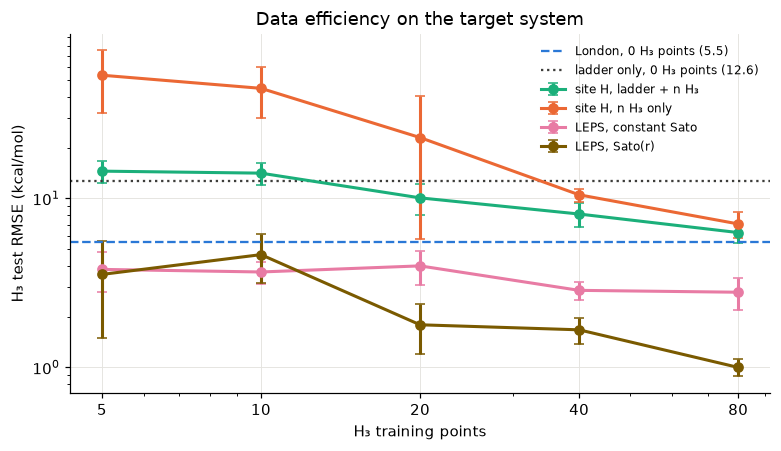

In [11]:
idx_win = np.where(M3)[0]
ns = [5, 10, 20, 40, 80]
few = {'site H, ladder + n H₃': [], 'site H, n H₃ only': [], 'LEPS, constant Sato': [], 'LEPS, Sato(r)': []}
def fit_leps(npar, sel):
    f = lambda c: np.concatenate([(leps(c, sel) - tri['H3'][sel]) * KCAL, 0.3 * c])
    return least_squares(f, np.zeros(npar)).x
for n in ns:
    a_l, a_o, a_1, a_6 = [], [], [], []
    for seed in range(3):
        sel = np.random.default_rng(seed).choice(idx_win, n, replace=False)
        test = np.setdiff1d(idx_win, sel)
        D['H3 few'] = Dataset('few', (3, 2, 1), [tri_xy[i] for i in sel], tri['H3'][sel])
        Dt = Dataset('test', (3, 2, 1), [tri_xy[i] for i in test], tri['H3'][test])
        a_l.append(rmse(Dt, fit(th3, BLOCKS, LADDER + ['H3 few'])))
        a_o.append(rmse(Dt, fit(theta, BLOCKS, ['H3 few'])))
        for npar, store in [(1, a_1), (6, a_6)]:
            c = fit_leps(npar, sel)
            store.append(np.sqrt(np.mean((leps(c, test) - tri['H3'][test]) ** 2)) * KCAL)
    for k, v in zip(few, [a_l, a_o, a_1, a_6]):
        few[k].append(v)
    print(f'n = {n:3d}: ' + '  '.join(f'{k} {np.mean(v):5.1f}±{np.std(v):3.1f}' for k, v in zip(few, [a_l, a_o, a_1, a_6])))

fig, ax = plt.subplots(figsize=(7.2, 4.2))
for (lab, v), col in zip(few.items(), [C3, C2, C4, '#7a5a00']):
    v = np.array(v)
    ax.errorbar(ns, v.mean(1), yerr=v.std(1), color=col, marker='o', ms=6, capsize=3, label=lab)
ax.axhline(rmse_lon, color=C1, ls='--', lw=1.5, label=f'London, 0 H₃ points ({rmse_lon:.1f})')
ax.axhline(rmse(D['H3'], th3), color=CREF, ls=':', lw=1.5, label=f'ladder only, 0 H₃ points ({rmse(D["H3"], th3):.1f})')
ax.set(xscale='log', yscale='log', xlabel='H₃ training points', ylabel='H₃ test RMSE (kcal/mol)',
       title='Data efficiency on the target system')
ax.set_xticks(ns); ax.set_xticklabels(ns)
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('ladder_fig4_fewshot.png', bbox_inches='tight'); plt.show()

## 8 · Where the errors are

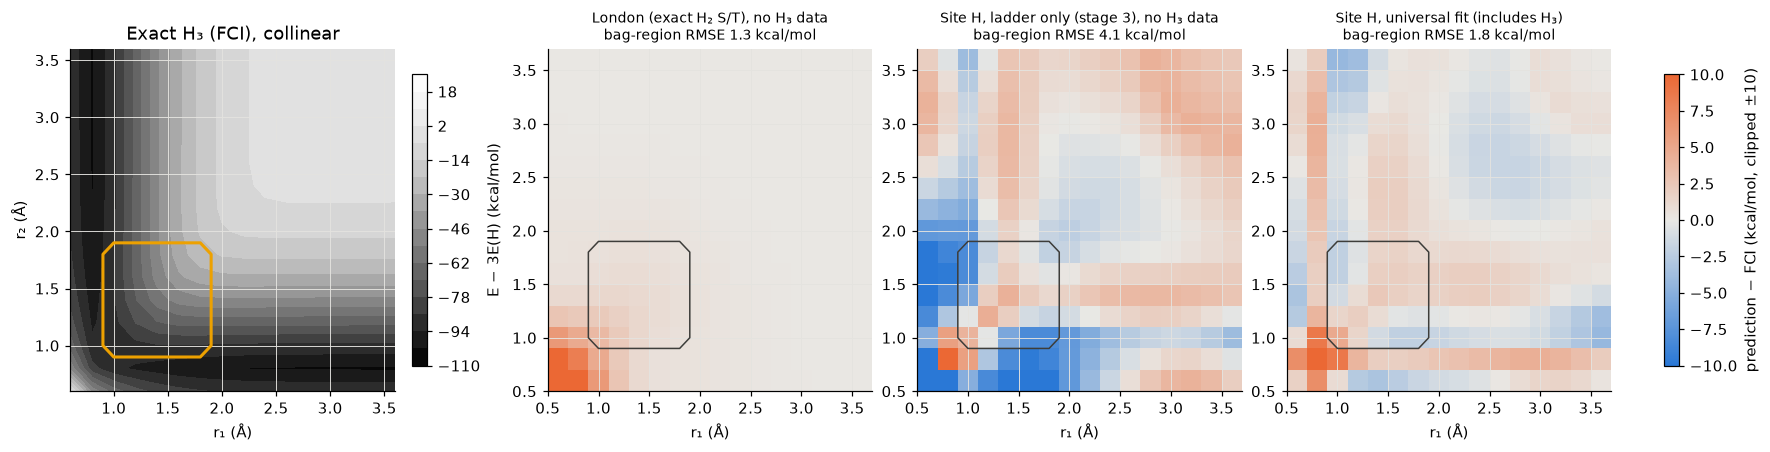

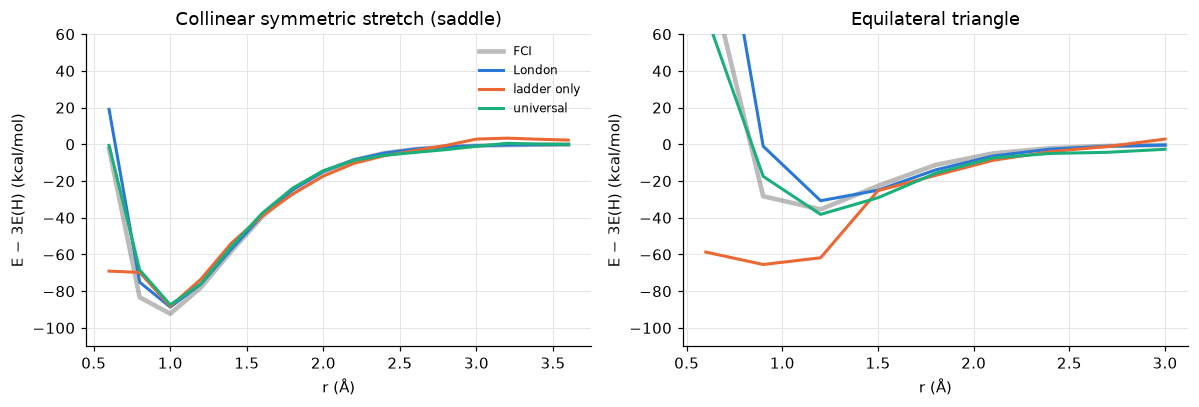

collinear barrier vs H + H2 (kcal/mol, grid estimate)
  FCI            11.3
  London         14.9
  ladder only    15.3
  universal      16.1


In [12]:
full = {'London': E_lon, 'ladder only': D_H3_all.predict(th3), 'universal': D_H3_all.predict(th_uni)}
names = {'London': 'London (exact H₂ S/T), no H₃ data', 'ladder only': 'Site H, ladder only (stage 3), no H₃ data',
         'universal': 'Site H, universal fit (includes H₃)'}
lin = geoms[:, 2] == 180.0
G1, G2 = geoms[lin, 0].reshape(16, 16), geoms[lin, 1].reshape(16, 16)
Eex = tri['H3'][lin].reshape(16, 16)
inwin = M3[lin].reshape(16, 16)
bag = (np.minimum(G1, G2) > 0.85) & (np.maximum(G1, G2) < 2.0)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.0), layout='constrained')
lv = np.arange(-110, 30, 8)
cs = axes[0].contourf(G1, G2, np.clip((Eex - 3 * E_H) * KCAL, -110, 30), levels=lv, cmap='Greys_r')
axes[0].contour(G1, G2, bag.astype(float), levels=[0.5], colors='#eda100', linewidths=2)
axes[0].set(title='Exact H₃ (FCI), collinear', xlabel='r₁ (Å)', ylabel='r₂ (Å)')
plt.colorbar(cs, ax=axes[0], label='E − 3E(H) (kcal/mol)', shrink=0.85)
lim = 10
for ax, lab in zip(axes[1:], full):
    err = np.where(inwin, (full[lab][lin].reshape(16, 16) - Eex) * KCAL, np.nan)
    im = ax.pcolormesh(G1, G2, np.clip(err, -lim, lim), cmap=DIVERGE, vmin=-lim, vmax=lim, shading='auto')
    ax.contour(G1, G2, bag.astype(float), levels=[0.5], colors=CREF, linewidths=1)
    ax.set(title=f'{names[lab]}\nbag-region RMSE {np.sqrt(np.nanmean(err[bag] ** 2)):.1f} kcal/mol', xlabel='r₁ (Å)')
    ax.title.set_fontsize(9)
plt.colorbar(im, ax=axes[1:], label='prediction − FCI (kcal/mol, clipped ±10)', shrink=0.85)
plt.savefig('ladder_fig1_h3_maps.png', bbox_inches='tight'); plt.show()

def cut(theta_deg):
    m = (geoms[:, 2] == theta_deg) & (geoms[:, 0] == geoms[:, 1])
    return geoms[m, 0], m
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, th, title in [(axes[0], 180.0, 'Collinear symmetric stretch (saddle)'), (axes[1], 60.0, 'Equilateral triangle')]:
    r, m = cut(th)
    ax.plot(r, (tri['H3'][m] - 3 * E_H) * KCAL, color=CREF, lw=3, alpha=0.35, label='FCI')
    for lab, col in zip(full, [C1, C2, C3]):
        ax.plot(r, (full[lab][m] - 3 * E_H) * KCAL, color=col, label=lab)
    ax.set(xlabel='r (Å)', ylabel='E − 3E(H) (kcal/mol)', title=title, ylim=(-110, 60))
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig('ladder_fig2_cuts.png', bbox_inches='tight'); plt.show()

r, m = cut(180.0)
print('collinear barrier vs H + H2 (kcal/mol, grid estimate)')
for lab, E in [('FCI', tri['H3'])] + list(full.items()):
    print(f'  {lab:12s} {(E[m].min() - E_H2H) * KCAL:6.1f}')

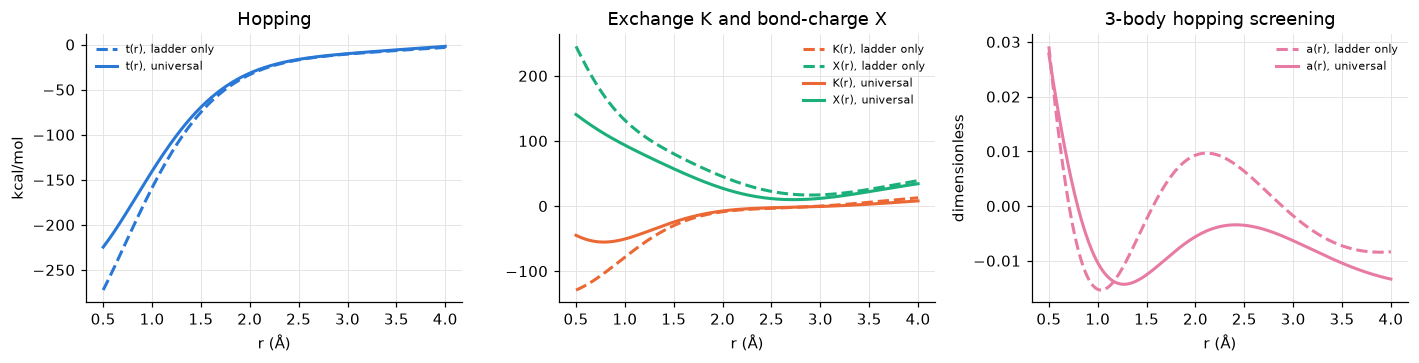

In [13]:
# the learned two-centre functions (universal fit) next to a bare overlap for scale
rr = np.linspace(0.5, 4.0, 200); Fr = slater_features(rr / BOHR)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for th, lab, ls in [(th3, 'ladder only', '--'), (th_uni, 'universal', '-')]:
    c = unpack(th)
    axes[0].plot(rr, Fr @ c['t'] * KCAL, color=C1, ls=ls, label=f't(r), {lab}')
    axes[1].plot(rr, Fr @ c['K'] * KCAL, color=C2, ls=ls, label=f'K(r), {lab}')
    axes[1].plot(rr, Fr @ c['X'] * KCAL, color=C3, ls=ls, label=f'X(r), {lab}')
    axes[2].plot(rr, Fr @ c['a'], color=C4, ls=ls, label=f'a(r), {lab}')
axes[0].set(title='Hopping', xlabel='r (Å)', ylabel='kcal/mol')
axes[1].set(title='Exchange K and bond-charge X', xlabel='r (Å)')
axes[2].set(title='3-body hopping screening', xlabel='r (Å)', ylabel='dimensionless')
for ax in axes: ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig('ladder_fig3_functions.png', bbox_inches='tight'); plt.show()

## 9 · Takeaways

All values are RMSE in kcal/mol against FCI/cc-pVDZ for H₃, over the scoring window ("low" = within 60 kcal/mol of H + H₂).

| Model | H₃ data used | H₃ RMSE | H₃ low |
|---|---|---|---|
| Site Hamiltonian, ladder (H₂⁺, H₃²⁺, H₂, H₃⁺) | 0 | 12.6 | 8.8 |
| Site Hamiltonian, ladder + H₃⁺ triplet + H₃²⁺ excited | 0 | 25.1 | 24.4 |
| London from exact H₂ singlet/triplet | 0 | 5.5 | 2.5 |
| Site Hamiltonian, one parameter set for every rung *and* H₃ | all | 2.9 | 3.0 |
| LEPS with learned Sato(r), 6 numbers | 20 / 80 | 1.8 / 1.0 | |

1. **The form is fine.** A single set of two-centre functions describes H₂⁺, H₂ (singlet and triplet), H₃²⁺ (ground and excited), H₃⁺ (singlet and triplet) and H₃ all at once, at 2–9 kcal/mol per state. One Hamiltonian really can span charge and spin states.
2. **The ladder alone doesn't determine it.** Every lower rung fits to a few kcal/mol, yet the H₃ prediction is poor, and adding *more* lower-rung states made it worse. The three-electron spin recoupling depends on combinations of hopping, exchange, bond-charge and on-site terms that 1- and 2-electron data don't separate. This is an identifiability problem, not a missing-physics problem.
3. **Fragment states transfer; orbital-level integrals don't.** The London equation uses the exact H₂ singlet and triplet curves as its diabatic building blocks, with all orbital relaxation and correlation already inside them. With zero H₃ data it beats the learned site Hamiltonian, and with a 6-number learned correction it reaches ~1–2 kcal/mol from 20–80 H₃ points. The site model needs ~80 points to get to 6.
4. **The ladder is still useful as a prior.** With 5–20 target points, ladder pretraining cuts the site-model error 2–4× relative to fitting the target data alone. In the collinear "bag" region, the ladder-only model (4.1 kcal/mol, zero H₃ data) is already comparable to the first notebook's descriptor models trained on 120 H₃ points (2.9–6.3), and nowhere near SOAP's 87.
5. **The learned functions are effective parameters, not integrals.** K(r) comes out negative at short range, for example, which a true exchange integral cannot be. Interpreting them physically needs care.

**What this suggests for Criegee intermediates:** build the diabatic matrix from *fragment states* (diatomics-in-molecules style), with each fragment's state curves learned once per atom-pair type, and learn only a small many-body correction from modest target data. The matrix size follows the number of chemically relevant structures, not the electron count. The hard parts move to choosing fragment states for heteroatoms (O ³P/¹D, ionic states) and keeping the diabats consistent, which is where historical DIM struggled and ML-learned fragment curves could help.

**Caveats:** one orbital per site in a minimal model; random training points; barrier heights read off a 0.2 Å grid; and H₃ is the friendliest possible case for London/LEPS, which was designed around it.